# Wine Quality Classification — Assignment 2

Reconstructed from the Python/Jupyter source export supplied in this conversation. Original executed outputs were not included, so run the notebook from top to bottom to regenerate results.

## Important execution notes
- Run all cells in order.
- The first code cell installs the packages used by the original work.
- The dataset is downloaded from the UCI Wine Quality repository.
- The red and white datasets are combined, with `color` retained as an input feature.
- The target column is `quality`.
- This notebook is a recovery copy, not yet the final audited submission. We will validate and improve it before packaging the GitHub repository and Streamlit app.

In [1]:
%pip install pandas numpy scikit-learn matplotlib seaborn joblib streamlit

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np

import urllib.request

# Download red wine dataset
red_url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/wine-quality/"
    "winequality-red.csv"
)

urllib.request.urlretrieve(
    red_url, "winequality-red.csv"
)

# Download white wine dataset
white_url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/wine-quality/"
    "winequality-white.csv"
)

urllib.request.urlretrieve(
    white_url, "winequality-white.csv"
)

print("Both datasets downloaded successfully!")

Both datasets downloaded successfully!


In [3]:
# Load red wine data
red_wine = pd.read_csv(
    "winequality-red.csv",
    sep=";"
)

# Load white wine data
white_wine = pd.read_csv(
    "winequality-white.csv",
    sep=";"
)

# Add wine colour as an input feature
red_wine["color"] = "red"
white_wine["color"] = "white"

# Combine both datasets
wine_data = pd.concat(
    [red_wine, white_wine],
    ignore_index=True
)

print("Dataset combined successfully!")
print(wine_data.head())

Dataset combined successfully!
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality color  
0      9.4        5   red  

In [4]:
print("Dataset dimensions:", wine_data.shape)

print("\nColumn names:")
print(wine_data.columns.tolist())

print("\nNumber of input features:",
      len(wine_data.columns) - 1)

print("\nNumber of records:",
      len(wine_data))

Dataset dimensions: (6497, 13)

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'color']

Number of input features: 12

Number of records: 6497


In [5]:
print("Quality values:")
print(sorted(wine_data["quality"].unique()))

print("\nQuality distribution:")
print(wine_data["quality"].value_counts().sort_index())

Quality values:
[np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

Quality distribution:
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


In [6]:
# Check missing values
print("Missing values:")
print(wine_data.isnull().sum())

# Check duplicate records
print("\nDuplicate records:",
      wine_data.duplicated().sum())

# Save combined dataset
wine_data.to_csv(
    "wine_quality_combined.csv",
    index=False
)

print("\nDataset saved successfully!")

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64

Duplicate records: 1177

Dataset saved successfully!


In [7]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Load prepared dataset
wine_data = pd.read_csv("wine_quality_combined.csv")

# Display first five records
display(wine_data.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [8]:
# Dataset dimensions
print("Dataset Shape:", wine_data.shape)

# Column information
print("\nDataset Information:")
wine_data.info()

# Statistical summary
print("\nStatistical Summary:")
display(wine_data.describe())

# Check data types
print("\nData Types:")
print(wine_data.dtypes)

Dataset Shape: (6497, 13)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 688.6 KB

Statistical Summary:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000



Data Types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object


In [9]:
# Check missing values
print("Missing values in each column:")
print(wine_data.isnull().sum())

# Total missing values
print("\nTotal Missing Values:",
      wine_data.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:",
      wine_data.duplicated().sum())

Missing values in each column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64

Total Missing Values: 0

Duplicate Records: 1177


quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


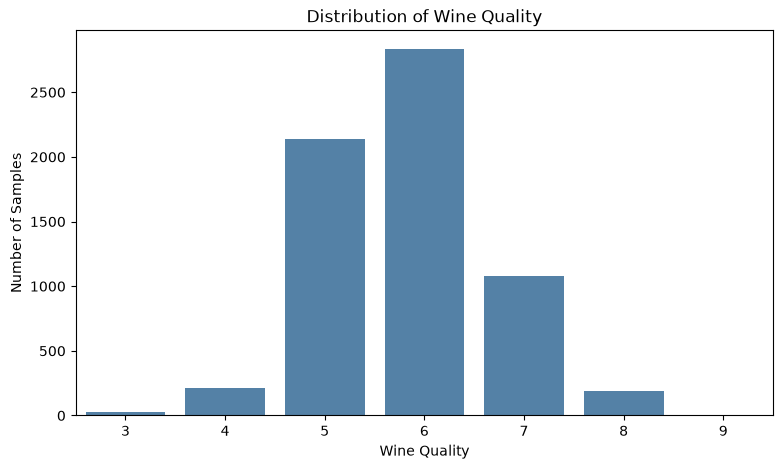

In [10]:
# Count each wine quality category
quality_counts = wine_data["quality"].value_counts().sort_index()

print(quality_counts)

# Plot target distribution
plt.figure(figsize=(9, 5))

sns.countplot(
    data=wine_data,
    x="quality",
    color="steelblue"
)

plt.title("Distribution of Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Samples")

plt.show()

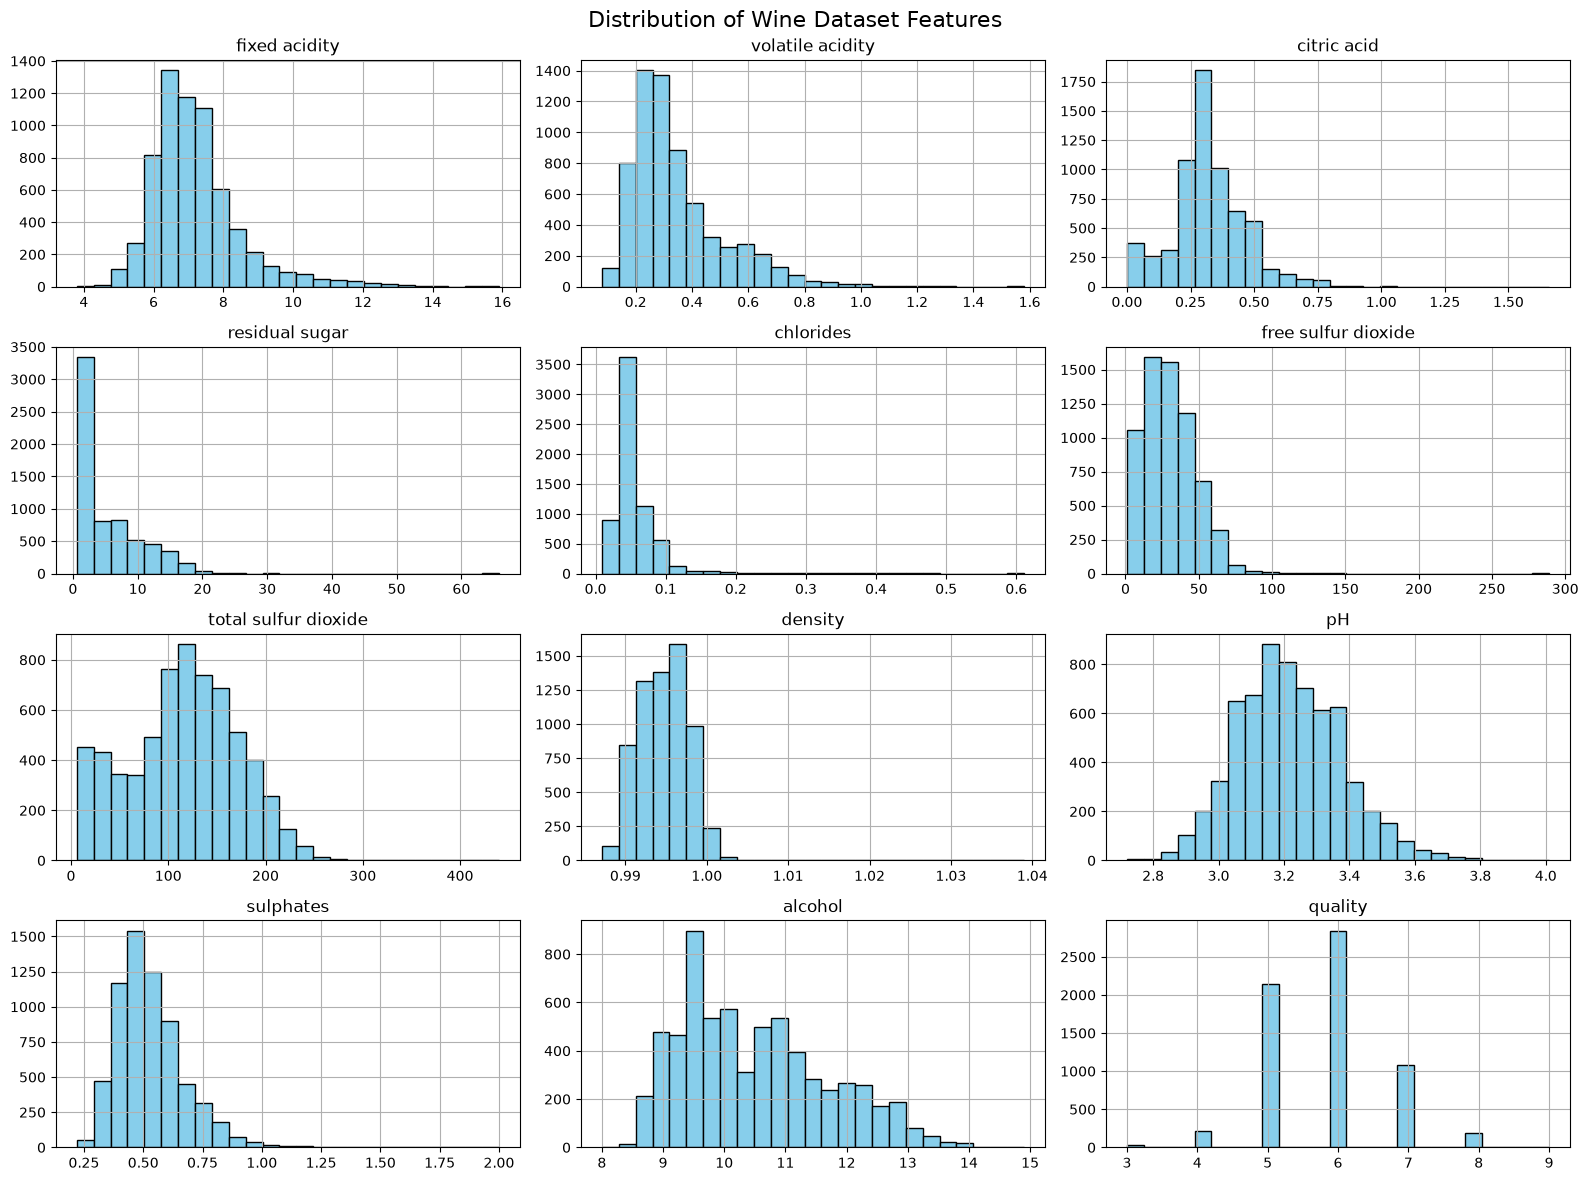

In [11]:
# Select numerical columns
numeric_columns = wine_data.select_dtypes(
    include=np.number
).columns

# Plot histograms
wine_data[numeric_columns].hist(
    figsize=(16, 12),
    bins=25,
    color="skyblue",
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Wine Dataset Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

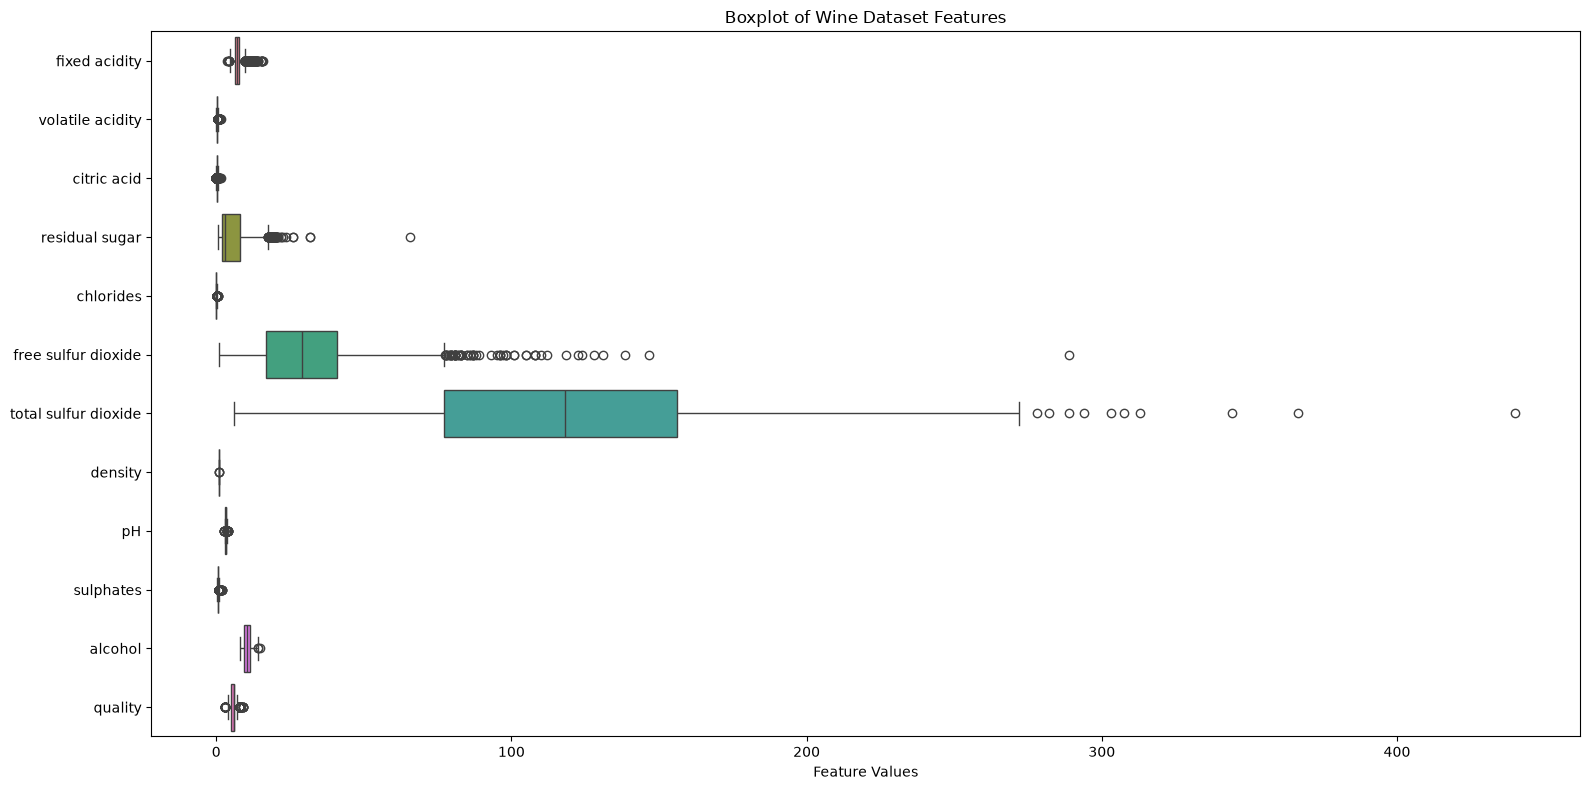

In [12]:
plt.figure(figsize=(16, 8))

sns.boxplot(
    data=wine_data[numeric_columns],
    orient="h"
)

plt.title("Boxplot of Wine Dataset Features")
plt.xlabel("Feature Values")

plt.tight_layout()
plt.show()

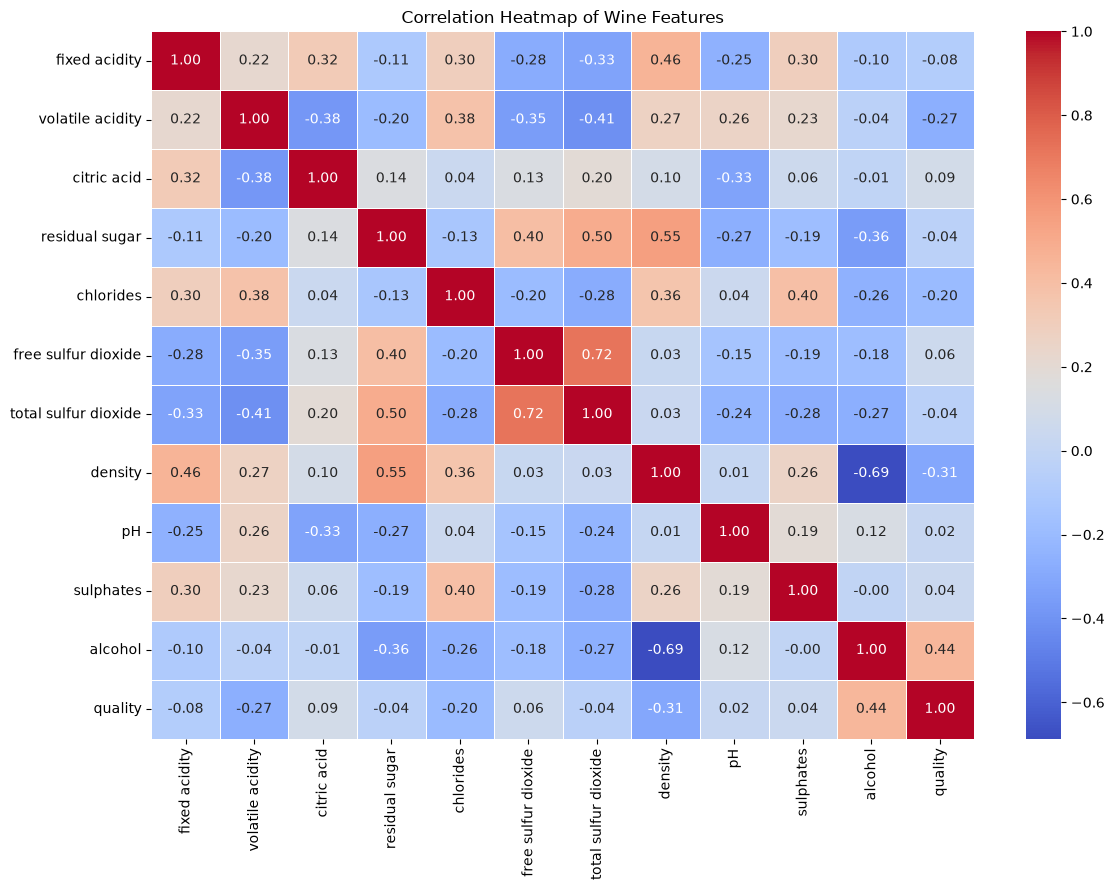

In [13]:
# Calculate correlation matrix
correlation_matrix = wine_data[
    numeric_columns
].corr()

# Visualize correlations
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Wine Features")

plt.tight_layout()
plt.show()

In [14]:
# Separate input features and target
X = wine_data.drop("quality", axis=1)

y = wine_data["quality"]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

Input feature shape: (6497, 12)
Target shape: (6497,)

Input features:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'color']


In [15]:
from sklearn.model_selection import train_test_split

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (5197, 12)
Testing data shape: (1300, 12)
Training target shape: (5197,)
Testing target shape: (1300,)


In [16]:
# Combine test features and target
test_data = X_test.copy()

test_data["quality"] = y_test

# Save test dataset
test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

Test dataset saved successfully!
Test dataset shape: (1300, 13)


In [17]:
# Data handling
import pandas as pd
import numpy as np

# Model preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Model saving
import joblib
import os

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [18]:
# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("\nPreprocessing pipeline created successfully!")

Numerical features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Categorical features: ['color']

Preprocessing pipeline created successfully!


In [19]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        probability=True,
        random_state=42
    )
}

print("Five classification models defined successfully!")

for model_name in models:
    print(model_name)

Five classification models defined successfully!
Logistic Regression
Decision Tree
KNN
Naive Bayes
Support Vector Machine


In [20]:
trained_models = {}

for model_name, classifier in models.items():

    print("\nTraining:", model_name)

    # Create complete pipeline
    model_pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ]
    )

    # Train model
    model_pipeline.fit(
        X_train,
        y_train
    )

    # Save trained pipeline
    trained_models[model_name] = model_pipeline

    print(model_name, "trained successfully!")

print("\nAll five models have been trained!")


Training: Logistic Regression
Logistic Regression trained successfully!

Training: Decision Tree
Decision Tree trained successfully!

Training: KNN
KNN trained successfully!

Training: Naive Bayes
Naive Bayes trained successfully!

Training: Support Vector Machine


C:\Users\suriy\PycharmProjects\MTECH_ML_ASSIGNMENT_2\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine trained successfully!

All five models have been trained!


In [21]:
# Create an empty list for storing results
results = []

for model_name, model_pipeline in trained_models.items():

    # Predict wine quality
    y_pred = model_pipeline.predict(X_test)

    # Calculate predicted probabilities
    y_prob = model_pipeline.predict_proba(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        average="weighted",
        labels=model_pipeline.classes_
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    mcc = matthews_corrcoef(
        y_test,
        y_pred
    )

    # Store results
    results.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

    print("\nEvaluation completed:", model_name)

print("\nAll models evaluated successfully!")


Evaluation completed: Logistic Regression

Evaluation completed: Decision Tree

Evaluation completed: KNN

Evaluation completed: Naive Bayes

Evaluation completed: Support Vector Machine

All models evaluated successfully!


In [22]:
# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Format numerical values
results_df = results_df.round(4)

# Display comparison table
print("MODEL PERFORMANCE COMPARISON")

display(results_df)

MODEL PERFORMANCE COMPARISON


,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.5415,0.7228,0.5424,0.5415,0.5142,0.2721
1,Decision Tree,0.5862,0.6955,0.5895,0.5862,0.5870,0.3893
2,KNN,0.5585,0.7389,0.5441,0.5585,0.5489,0.3259
3,Naive Bayes,0.2215,0.5525,0.3960,0.2215,0.2751,0.0697
4,Support Vector Machine,0.5692,0.7613,0.5360,0.5692,0.5352,0.3158


In [23]:
results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison results saved!")

Model comparison results saved!


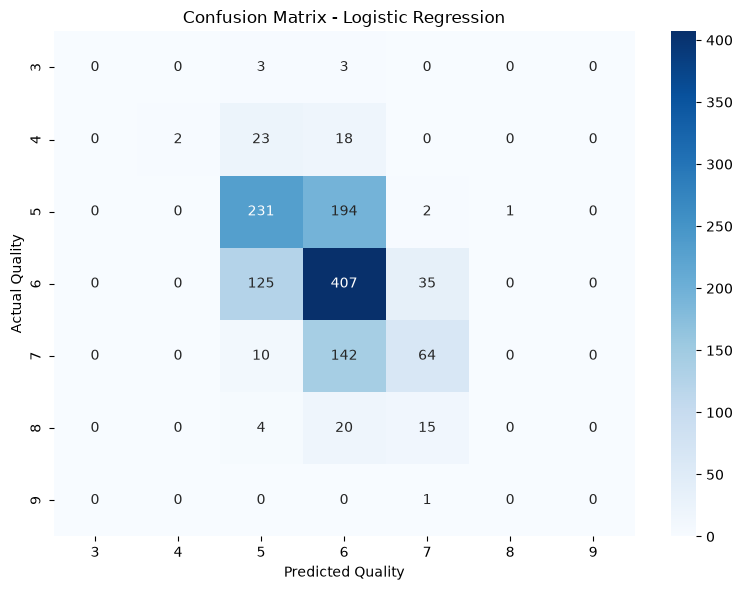

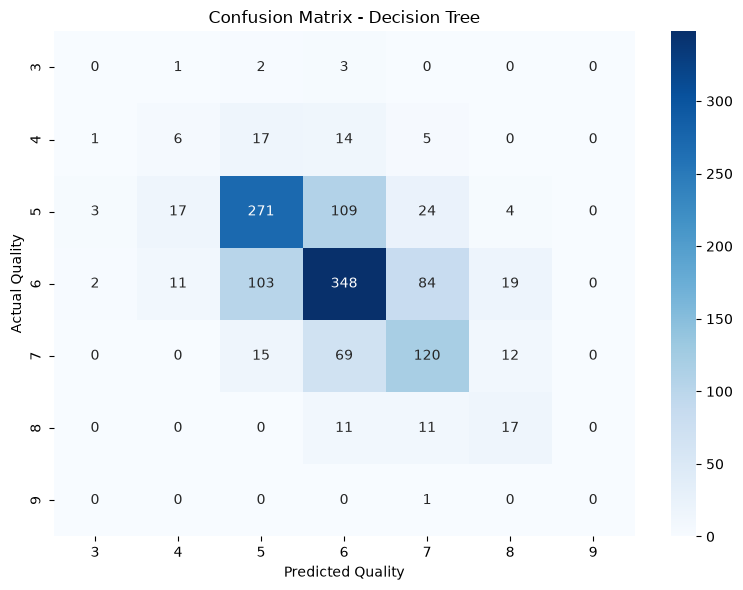

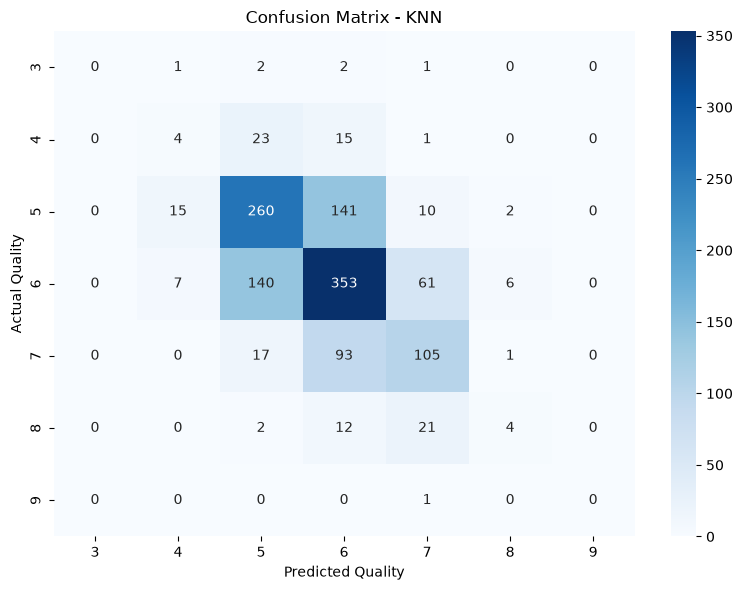

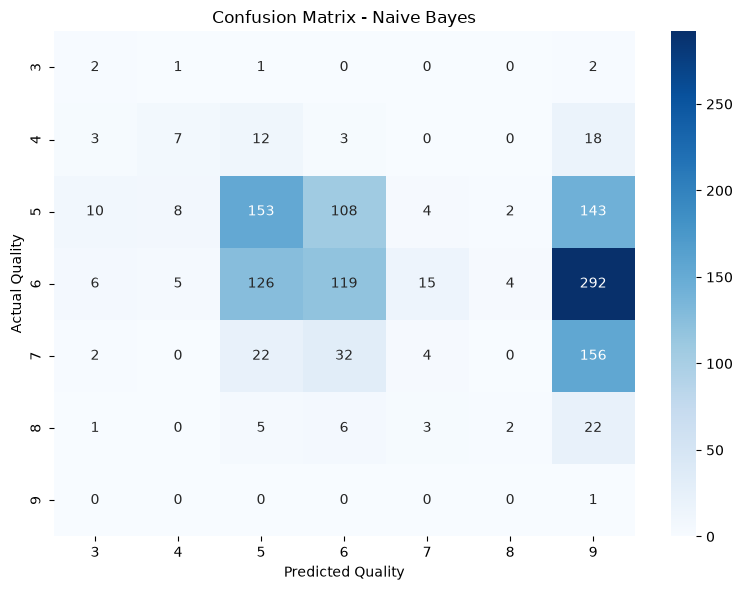

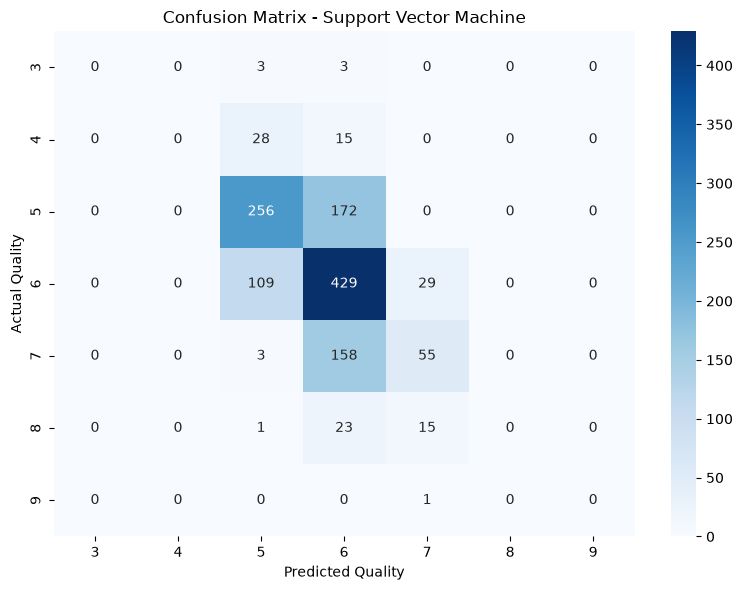

In [24]:
for model_name, model_pipeline in trained_models.items():

    # Generate predictions
    y_pred = model_pipeline.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=model_pipeline.classes_
    )

    # Plot confusion matrix
    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model_pipeline.classes_,
        yticklabels=model_pipeline.classes_
    )

    plt.title(
        f"Confusion Matrix - {model_name}"
    )

    plt.xlabel("Predicted Quality")
    plt.ylabel("Actual Quality")

    plt.tight_layout()
    plt.show()

In [25]:
for model_name, model_pipeline in trained_models.items():

    y_pred = model_pipeline.predict(X_test)

    print("\n" + "=" * 60)
    print("CLASSIFICATION REPORT:", model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       1.00      0.05      0.09        43
           5       0.58      0.54      0.56       428
           6       0.52      0.72      0.60       567
           7       0.55      0.30      0.38       216
           8       0.00      0.00      0.00        39
           9       0.00      0.00      0.00         1

    accuracy                           0.54      1300
   macro avg       0.38      0.23      0.23      1300
weighted avg       0.54      0.54      0.51      1300


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.17      0.14      0.15        43
           5       0.66      0.63      0.65       428
           6       0.63      0.61      0.62       567
           7       0.49      0.56      0.52       

In [26]:
# Create model directory
os.makedirs("model", exist_ok=True)

# Define filenames
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

# Save all trained models
for model_name, model_pipeline in trained_models.items():

    filename = model_files[model_name]

    filepath = os.path.join(
        "model",
        filename
    )

    joblib.dump(
        model_pipeline,
        filepath
    )

    print("Saved:", filepath)

print("\nAll five trained models saved successfully!")

Saved: model\logistic_regression.joblib
Saved: model\decision_tree.joblib
Saved: model\knn.joblib
Saved: model\naive_bayes.joblib
Saved: model\svm.joblib

All five trained models saved successfully!


In [27]:
# Load saved Logistic Regression model
loaded_model = joblib.load(
    "model/logistic_regression.joblib"
)

# Test prediction
sample_prediction = loaded_model.predict(
    X_test.iloc[:5]
)

print("Model loaded successfully!")

print("\nSample predictions:")
print(sample_prediction)

Model loaded successfully!

Sample predictions:
[6 6 6 6 6]


In [28]:
# Find the model with the highest F1 score
best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("BEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_model["ML Model Name"])
print("Accuracy:", best_model["Accuracy"])
print("AUC:", best_model["AUC"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1 Score:", best_model["F1 Score"])
print("MCC:", best_model["MCC"])

BEST PERFORMING MODEL
---------------------
Model: Decision Tree
Accuracy: 0.5862
AUC: 0.6955
Precision: 0.5895
Recall: 0.5862
F1 Score: 0.587
MCC: 0.3893


In [29]:
import pandas as pd

# Load model comparison results
results_df = pd.read_csv(
    "model_comparison_results.csv"
)

# Display results
display(results_df)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.5415,0.7228,0.5424,0.5415,0.5142,0.2721
1,Decision Tree,0.5862,0.6955,0.5895,0.5862,0.5870,0.3893
2,KNN,0.5585,0.7389,0.5441,0.5585,0.5489,0.3259
3,Naive Bayes,0.2215,0.5525,0.3960,0.2215,0.2751,0.0697
4,Support Vector Machine,0.5692,0.7613,0.5360,0.5692,0.5352,0.3158


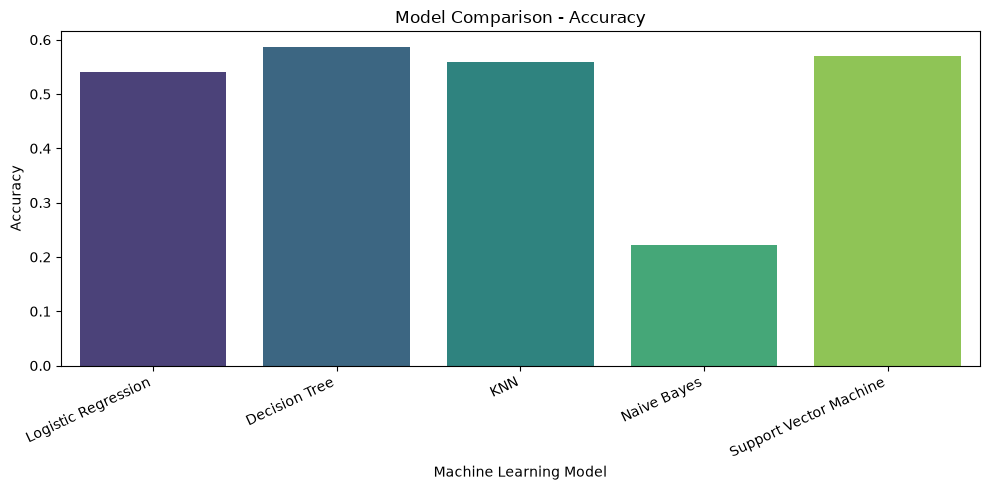

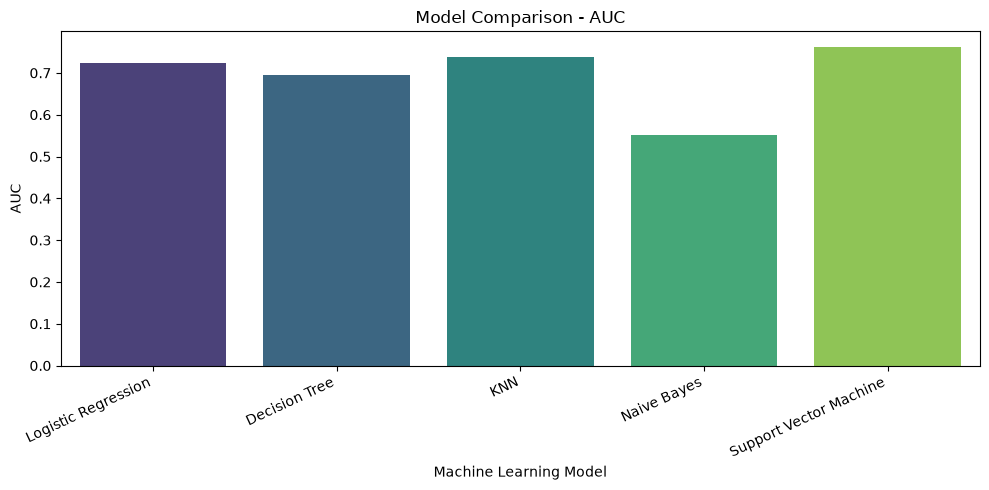

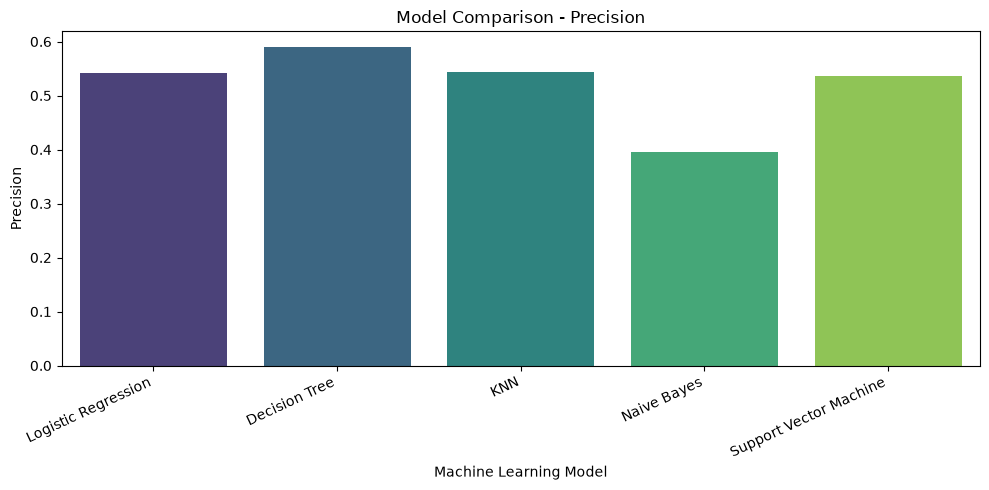

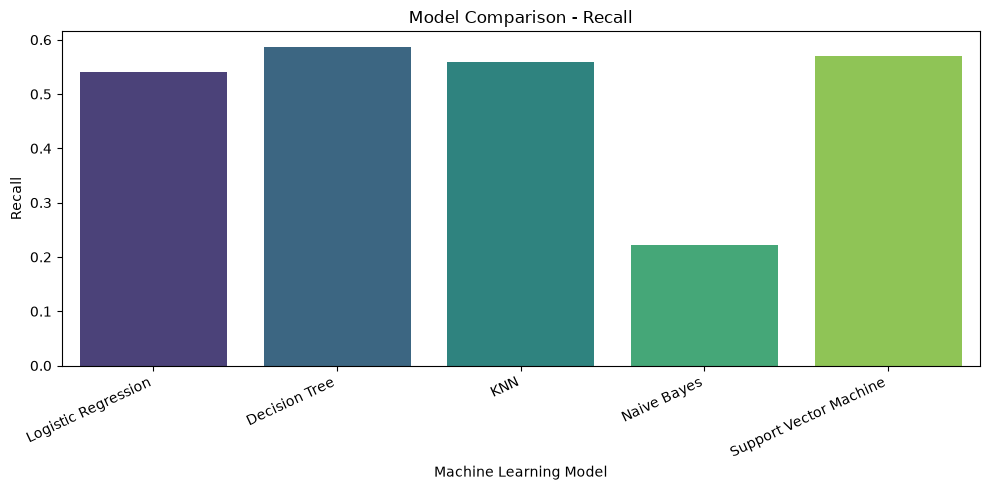

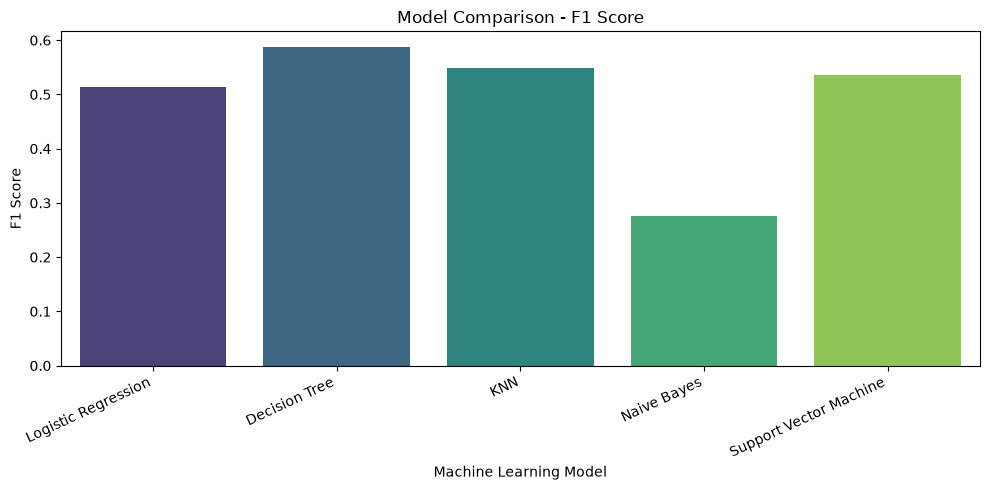

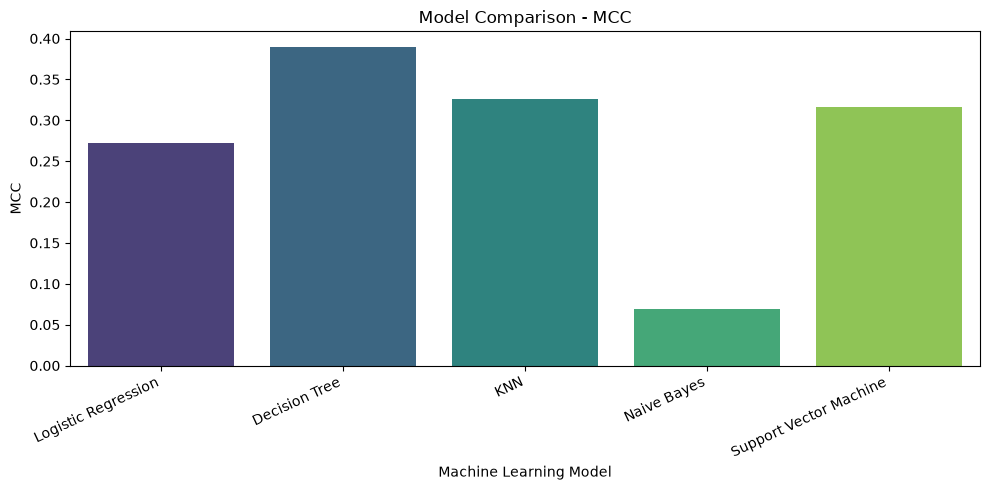

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="ML Model Name",
        y=metric,
        hue="ML Model Name",
        palette="viridis",
        legend=False
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Machine Learning Model")
    plt.ylabel(metric)

    plt.xticks(rotation=25, ha="right")

    plt.tight_layout()
    plt.show()

In [31]:
metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

print("BEST MODEL FOR EACH METRIC")
print("=" * 45)

for metric in metrics:

    best_index = results_df[metric].idxmax()

    best_name = results_df.loc[
        best_index, "ML Model Name"
    ]

    best_value = results_df.loc[
        best_index, metric
    ]

    print(
        f"{metric}: {best_name} ({best_value:.4f})"
    )

BEST MODEL FOR EACH METRIC
Accuracy: Decision Tree (0.5862)
AUC: Support Vector Machine (0.7613)
Precision: Decision Tree (0.5895)
Recall: Decision Tree (0.5862)
F1 Score: Decision Tree (0.5870)
MCC: Decision Tree (0.3893)


In [32]:
final_table = results_df[
    [
        "ML Model Name",
        "Accuracy",
        "AUC",
        "Precision",
        "Recall",
        "F1 Score",
        "MCC"
    ]
].copy()

# Round values to four decimal places
final_table.iloc[:, 1:] = (
    final_table.iloc[:, 1:].round(4)
)

display(final_table)

# Save the final table
final_table.to_csv(
    "final_model_comparison.csv",
    index=False
)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.5415,0.7228,0.5424,0.5415,0.5142,0.2721
1,Decision Tree,0.5862,0.6955,0.5895,0.5862,0.5870,0.3893
2,KNN,0.5585,0.7389,0.5441,0.5585,0.5489,0.3259
3,Naive Bayes,0.2215,0.5525,0.3960,0.2215,0.2751,0.0697
4,Support Vector Machine,0.5692,0.7613,0.5360,0.5692,0.5352,0.3158


In [33]:
import joblib
import numpy as np

# Check every saved model
model_paths = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "KNN": "model/knn.joblib",
    "Naive Bayes": "model/naive_bayes.joblib",
    "Support Vector Machine": "model/svm.joblib"
}

for model_name, path in model_paths.items():

    loaded_model = joblib.load(path)

    # Compare predictions
    original_predictions = trained_models[
        model_name
    ].predict(X_test)

    loaded_predictions = loaded_model.predict(
        X_test
    )

    print(
        model_name,
        ":",
        np.array_equal(
            original_predictions,
            loaded_predictions
        )
    )

Logistic Regression : True
Decision Tree : True
KNN : True
Naive Bayes : True
Support Vector Machine : True
